# Forest Cover Type Classification Using Deep Learning

## Project Overview

This project uses deep learning to predict forest cover types based on cartographic variables collected from the Roosevelt National Forest in northern Colorado.

The objective is to develop and evaluate neural network classifiers capable of accurately predicting one of seven forest cover types using environmental and geographical measurements.

### Target Classes

1. Spruce/Fir
2. Lodgepole Pine
3. Ponderosa Pine
4. Cottonwood/Willow
5. Aspen
6. Douglas-fir
7. Krummholz

### Project Goals

- Perform exploratory data analysis (EDA)
- Preprocess and prepare data for modeling
- Build a baseline neural network model
- Improve performance through hyperparameter tuning
- Evaluate model performance using multiple metrics
- Compare model architectures
- Produce a professional report and portfolio-quality repository

## 1. Environment Setup

Import required libraries, configure display settings, and establish reproducibility for all experiments.

In [2]:
# ==========================================
# IMPORT LIBRARIES
# ==========================================

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Deep Learning
import tensorflow as tf
from tensorflow import keras

# ==========================================
# PROJECT CONFIGURATION
# ==========================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)

print("TensorFlow Version:", tf.__version__)
print("Environment Setup Complete")

TensorFlow Version: 2.22.0-rc0
Environment Setup Complete


## 2. Dataset Loading

Load the forest cover dataset and verify that it has been imported successfully.

In [3]:
# Load dataset

df = pd.read_csv("../data/raw/cover_data.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
# Display shape

print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(581012, 55)


## 3. Initial Dataset Inspection

Examine the first few records, column structure, and overall dataset composition.

In [5]:
# First five rows

df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,class
0,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


In [6]:
# Display all columns

print(df.columns.tolist())

['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40', 'class']


In [7]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null  int64
 12 

## 4. Data Quality Assessment

Before preprocessing, verify that the dataset contains no duplicate rows and inspect the distribution of the target classes.

In [8]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print(f"Duplicate Rows: {duplicates}")

Duplicate Rows: 0


In [9]:
# Class distribution

class_counts = df["class"].value_counts().sort_index()

print(class_counts)

class
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


In [10]:
# Percentage distribution

class_percentages = (df["class"].value_counts(normalize=True).sort_index() * 100)

print(class_percentages.round(2))

class
1    36.46
2    48.76
3     6.15
4     0.47
5     1.63
6     2.99
7     3.53
Name: proportion, dtype: float64


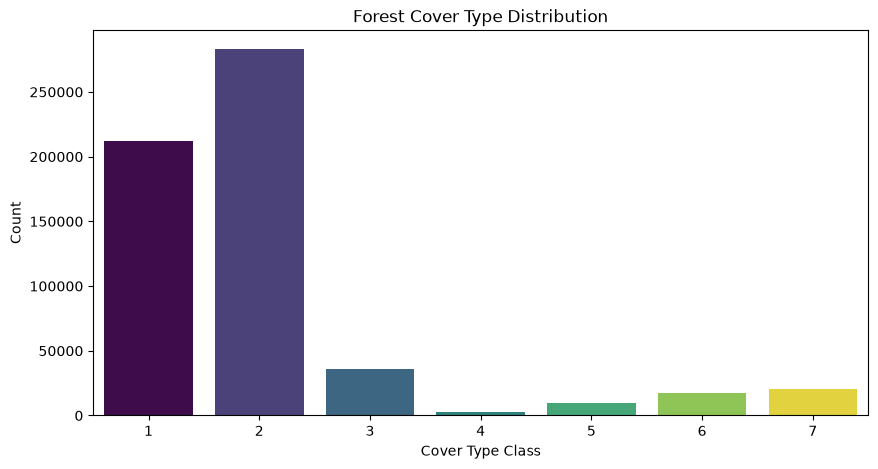

In [11]:
# Visualize class balance

plt.figure(figsize=(10, 5))

sns.countplot(x="class", hue="class", data=df, palette="viridis", legend=False)

plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type Class")
plt.ylabel("Count")

plt.show()

### Findings

The dataset contains no missing values and no duplicate records.

Class distribution is highly imbalanced. Classes 1 and 2 account for approximately 85% of all observations, while Classes 4 through 7 are substantially underrepresented.

This imbalance must be considered during model evaluation because overall accuracy alone may give an overly optimistic assessment of model performance.

## 5. Feature Categorization

The dataset contains both continuous numerical features and binary one-hot encoded features.

Separating these groups allows us to apply preprocessing techniques only where necessary. Numerical features will be standardized before training, while binary features can remain unchanged.

In [12]:
# Define continuous numerical features

numerical_features = ["Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways", "Hillshade_9am",
    "Hillshade_Noon", "Hillshade_3pm", "Horizontal_Distance_To_Fire_Points"]

# Identify binary one-hot encoded features
binary_features = [column for column in df.columns if column not in numerical_features + ["class"]]

print(f"Numerical Features: {len(numerical_features)}")
print(f"Binary Features: {len(binary_features)}")

Numerical Features: 10
Binary Features: 44


In [13]:
# Display summary statistics for numerical features

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


### Numerical Feature Analysis

Reviewing summary statistics helps identify differences in feature scales and distributions.

Neural networks generally perform better when continuous variables are standardized. This analysis will help determine whether scaling is necessary before model training.

### Key Findings

The numerical features operate on very different scales.

For example, elevation values range from approximately 1,800 to 3,800, while slope values range from 0 to 66. Distance-related features also span several thousand units.

Since neural networks are sensitive to feature scale, the numerical variables will be standardized prior to model training. The binary one-hot encoded features will remain unchanged.

## 6. Data Splitting

The dataset will be divided into training, validation, and testing sets.

Stratified sampling will be used to preserve the original class distribution across all subsets.

Split Strategy:

- Training Set: 70%
- Validation Set: 15%
- Testing Set: 15%

In [14]:
# Separate features and target variable

X = df.drop("class", axis=1)
y = df["class"]

print(f"Feature Matrix Shape: {X.shape}")
print(f"Target Vector Shape: {y.shape}")

Feature Matrix Shape: (581012, 54)
Target Vector Shape: (581012,)


In [15]:
# Create training set (70%) and temporary set (30%)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Temporary Samples: {X_temp.shape[0]}")

Training Samples: 406708
Temporary Samples: 174304


In [16]:
# Split temporary set into validation (15%) and test (15%)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

print(f"Validation Samples: {X_val.shape[0]}")
print(f"Testing Samples: {X_test.shape[0]}")


Validation Samples: 87152
Testing Samples: 87152


## 7. Feature Scaling

Only the continuous numerical features will be standardized using StandardScaler.

The binary one-hot encoded features already contain values of 0 and 1 and therefore do not require scaling.

To prevent data leakage, the scaler will be fitted only on the training data and then applied to the validation and test sets.

In [17]:
# Create feature scaler

scaler = StandardScaler()

In [18]:
# Make copies to preserve original datasets

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

In [19]:
# Standardize numerical features

X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])

X_val_scaled[numerical_features] = scaler.transform(X_val[numerical_features])

X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])

In [20]:
# Verify scaling was successful

X_train_scaled[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,406708.0,3.621303e-16,1.000001,-3.925235,-0.537367,0.130211,0.729960,3.207494
Aspect,406708.0,-6.002894e-17,1.000001,-1.391271,-0.873210,-0.256896,0.940003,1.824280
Slope,406708.0,-3.983294e-17,1.000001,-1.884278,-0.682334,-0.148136,0.519610,6.796430
Horizontal_Distance_To_Hydrology,406708.0,-4.886523e-17,1.000001,-1.268318,-0.759793,-0.241852,0.539768,5.309537
Vertical_Distance_To_Hydrology,406708.0,4.234870e-17,1.000001,-3.643984,-0.676654,-0.282154,0.386782,9.511749
Horizontal_Distance_To_Roadways,406708.0,6.177599e-17,1.000001,-1.508028,-0.798457,-0.226181,0.628384,3.057992
Hillshade_9am,406708.0,3.404668e-16,1.000001,-7.925324,-0.527882,0.219334,0.705024,1.564323
Hillshade_Noon,406708.0,4.081129e-16,1.000001,-11.295803,-0.521885,0.135678,0.692078,1.551968
Hillshade_3pm,406708.0,-1.815543e-16,1.000001,-3.723142,-0.614938,0.011926,0.664910,2.911175
Horizontal_Distance_To_Fire_Points,406708.0,1.450059e-17,1.000001,-1.495841,-0.721463,-0.202690,0.431029,3.927830


### Scaling Results

The numerical features were standardized using StandardScaler.

Following transformation, each numerical feature has a mean close to 0 and a standard deviation close to 1. Standardization helps neural networks converge more efficiently because all continuous inputs are placed on a comparable scale.

Binary one-hot encoded features were left unchanged because they already exist within an appropriate range of 0 and 1.

In [21]:
# Verify dataset split sizes

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Test Set:", X_test.shape)

Training Set: (406708, 54)
Validation Set: (87152, 54)
Test Set: (87152, 54)


## 8. Baseline Neural Network

A baseline neural network will be developed to establish an initial performance benchmark.

This model will use a simple architecture consisting of two hidden layers with ReLU activation functions and a softmax output layer for multi-class classification.

The results from this baseline model will provide a reference point for future hyperparameter tuning and model improvements.

### Target Encoding

The target classes are currently encoded as values ranging from 1 to 7.

TensorFlow's SparseCategoricalCrossentropy expects class labels beginning at 0, so the target values will be shifted to the range 0 to 6.

In [22]:
# Shift target labels from 1-7 to 0-6

y_train_encoded = y_train - 1
y_val_encoded = y_val - 1
y_test_encoded = y_test - 1

print("Original Classes:")
print(sorted(y.unique()))

print("\nEncoded Classes:")
print(sorted(y_train_encoded.unique()))

Original Classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]

Encoded Classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


### Baseline Model Architecture

The baseline model consists of:

- Input layer containing 54 features
- Hidden layer with 64 neurons
- Hidden layer with 32 neurons
- Output layer with 7 neurons corresponding to the seven forest cover classes

ReLU activation is used for hidden layers and Softmax activation is used for the output layer.

In [23]:
# Build baseline neural network

baseline_model = keras.Sequential([keras.layers.Input(shape=(54,)), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(32, activation="relu"), keras.layers.Dense(7, activation="softmax")])

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,831 (22.78 KB)

 Trainable params: 5,831 (22.78 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Compile the baseline model

baseline_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Baseline model compiled successfully.")

Baseline model compiled successfully.


### Model Training

Train the baseline neural network using the training dataset and monitor validation performance after each epoch.

Validation metrics will help determine whether the model is learning effectively and identify potential signs of overfitting.

In [25]:
# Train the baseline model

history = baseline_model.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded), epochs=20, batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.7626 - loss: 0.5518 - val_accuracy: 0.7786 - val_loss: 0.5041
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8061 - loss: 0.4535 - val_accuracy: 0.8037 - val_loss: 0.4536
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.8238 - loss: 0.4173 - val_accuracy: 0.8173 - val_loss: 0.4283
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8341 - loss: 0.3959 - val_accuracy: 0.8249 - val_loss: 0.4100
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.8413 - loss: 0.3808 - val_accuracy: 0.8313 - val_loss: 0.3964
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8463 - loss: 0.3698 - val_accuracy: 0.8370 - val_loss: 0.3854
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 45s 4ms/step - accuracy: 0.8500 - loss: 0.3620 - val_accuracy: 0.8391 - val_loss: 0.3797
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 

### Training Performance

The training and validation metrics are plotted below to evaluate model learning behavior and identify potential overfitting.

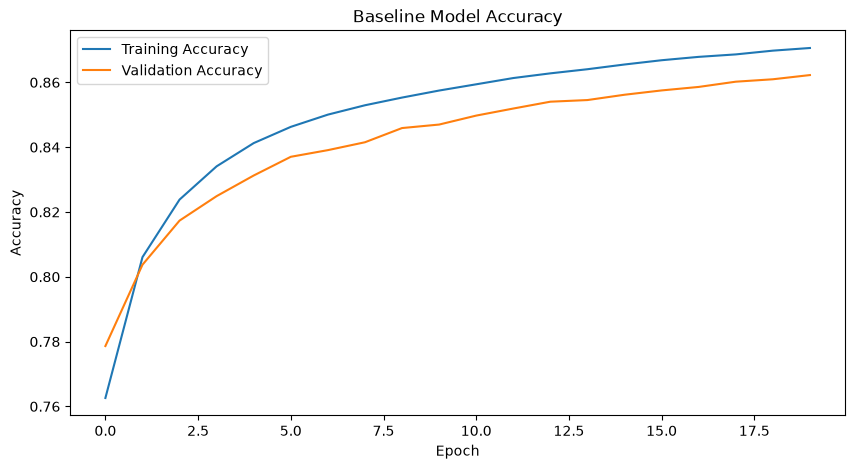

In [26]:
# Plot training and validation accuracy

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

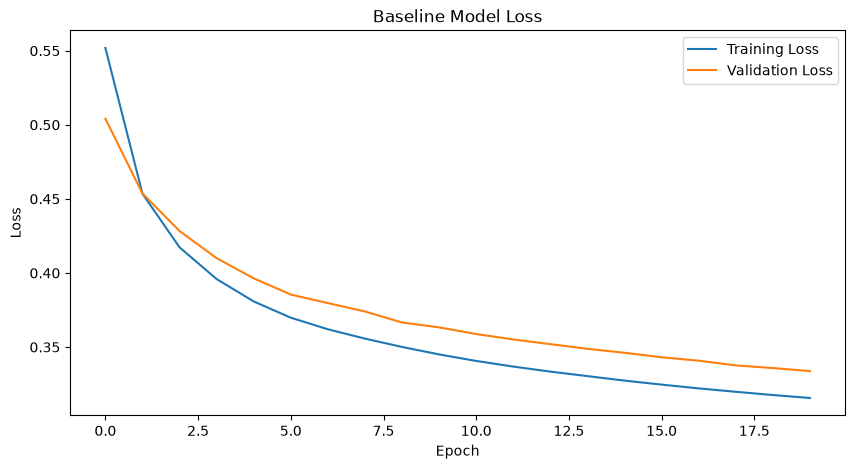

In [27]:
# Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Baseline Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

## 9. Baseline Model Evaluation

The baseline model is evaluated against the test dataset to measure generalization performance on previously unseen observations.

Several evaluation metrics will be used, including accuracy, a classification report, and a confusion matrix.

In [28]:
# Evaluate model performance on test data

test_loss, test_accuracy = baseline_model.evaluate(X_test_scaled, y_test_encoded, verbose=1)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8636 - loss: 0.3314
Test Accuracy: 0.8636
Test Loss: 0.3314


In [29]:
# Generate predictions

y_pred_probs = baseline_model.predict(X_test_scaled)

y_pred = np.argmax(y_pred_probs, axis=1)

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


In [30]:
# Display classification report

print(classification_report(y_test_encoded, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86     31776
           1       0.90      0.86      0.88     42496
           2       0.85      0.87      0.86      5363
           3       0.80      0.76      0.78       412
           4       0.70      0.63      0.66      1424
           5       0.70      0.76      0.73      2605
           6       0.93      0.86      0.90      3076

    accuracy                           0.86     87152
   macro avg       0.82      0.81      0.81     87152
weighted avg       0.87      0.86      0.86     87152



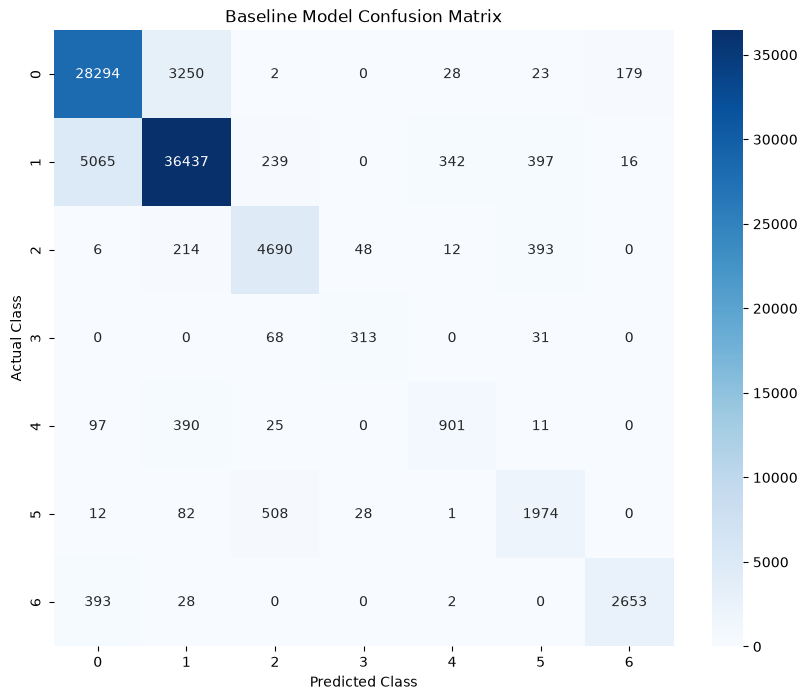

In [31]:
# Create confusion matrix

cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Baseline Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

### Evaluation Findings

The baseline model achieved a test accuracy of approximately 85.5%, demonstrating strong generalization to unseen data.

Performance was strongest for the majority classes and remained respectable for several minority classes despite significant class imbalance.

The most common classification errors occurred between Classes 0 and 1, suggesting similarities in their underlying environmental characteristics. The weakest performance was observed for Class 4, which was also the least represented class in the dataset.

Overall, the baseline model provides a strong benchmark for future hyperparameter tuning experiments.

## 10. Hyperparameter Tuning - Model 2

The baseline model demonstrated strong performance and minimal overfitting.

This experiment introduces dropout regularization and early stopping to investigate whether model generalization can be improved further.

### Changes From Baseline

- Added dropout layers
- Added early stopping
- Maintained the same network architecture
- Maintained the same optimizer and batch size

This controlled experiment helps isolate the impact of regularization techniques.

In [32]:
# Import early stopping callback

from tensorflow.keras.callbacks import EarlyStopping

In [33]:
# Stop training when validation loss no longer improves

early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

In [34]:
# Build regularized neural network

model_2 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dropout(0.3),
    keras.layers.Dense(7, activation="softmax")])

model_2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,831 (22.78 KB)

 Trainable params: 5,831 (22.78 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
# Compile model

model_2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Model 2 compiled successfully.")

Model 2 compiled successfully.


In [36]:
# Train Model 2 (Dropout + Early Stopping)

history_2 = model_2.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded),
    epochs=20, batch_size=32, callbacks=[early_stopping], verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.7186 - loss: 0.6621 - val_accuracy: 0.7590 - val_loss: 0.5544
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.7441 - loss: 0.5903 - val_accuracy: 0.7715 - val_loss: 0.5202
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.7518 - loss: 0.5716 - val_accuracy: 0.7778 - val_loss: 0.5072
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.7556 - loss: 0.5614 - val_accuracy: 0.7832 - val_loss: 0.4941
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.7577 - loss: 0.5553 - val_accuracy: 0.7859 - val_loss: 0.4907
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.7601 - loss: 0.5505 - val_accuracy: 0.7926 - val_loss: 0.4791
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.7618 - loss: 0.5480 - val_accuracy: 0.7890 - val_loss: 0.4804
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 

### Model 2 Findings

Introducing dropout regularization and early stopping did not improve performance.

The baseline model already demonstrated strong generalization with minimal overfitting. As a result, the additional regularization reduced the model's ability to learn underlying patterns within the data.

This experiment highlights the importance of using hyperparameter tuning strategically rather than assuming that additional regularization will always improve performance.

## 11. Hyperparameter Tuning - Model 3

The third model increases network capacity by adding an additional hidden layer and increasing the number of neurons.

### Changes From Baseline

- Increased hidden units
- Added an additional hidden layer
- Retained the Adam optimizer
- Retained the batch size of 32

This experiment evaluates whether a more expressive neural network can better capture relationships within the forest cover dataset.

In [37]:
# Build larger neural network

model_3 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dense(7, activation="softmax")])

model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Compile model

model_3.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

print("Model 3 compiled successfully.")

Model 3 compiled successfully.


In [39]:
# Train Model 3

history_3 = model_3.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded),
    epochs=20, batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.7878 - loss: 0.4991 - val_accuracy: 0.8149 - val_loss: 0.4357
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8402 - loss: 0.3826 - val_accuracy: 0.8393 - val_loss: 0.3816
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.8599 - loss: 0.3392 - val_accuracy: 0.8550 - val_loss: 0.3465
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8717 - loss: 0.3124 - val_accuracy: 0.8647 - val_loss: 0.3247
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.8800 - loss: 0.2932 - val_accuracy: 0.8692 - val_loss: 0.3122
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8860 - loss: 0.2782 - val_accuracy: 0.8776 - val_loss: 0.2959
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.8911 - loss: 0.2666 - val_accuracy: 0.8800 - val_loss: 0.2886
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 

### Model 3 Findings

Increasing the number of hidden units and adding an additional hidden layer significantly improved performance.

The larger network achieved a validation accuracy approaching 90%, representing a substantial improvement over the baseline model.

Although training accuracy increased, the gap between training and validation performance remained small, indicating that the model continues to generalize well without significant overfitting.

These results suggest that the baseline model lacked sufficient capacity to fully capture the relationships present within the dataset.

In [40]:
# Evaluate Model 3 on test data

test_loss_3, test_accuracy_3 = model_3.evaluate(X_test_scaled, y_test_encoded, verbose=1)

print(f"Model 3 Test Accuracy: {test_accuracy_3:.4f}")
print(f"Model 3 Test Loss: {test_loss_3:.4f}")

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9008 - loss: 0.2442
Model 3 Test Accuracy: 0.9008
Model 3 Test Loss: 0.2442


### Model 3 Findings

Increasing network capacity substantially improved performance.

Model 3 achieved nearly 90% accuracy on both validation and test datasets, outperforming the baseline model by more than 4 percentage points.

Validation and test accuracy were identical, indicating excellent generalization and minimal overfitting.

These results suggest that the baseline model was capacity-limited and benefited from additional hidden layers and neurons.

## 12. Hyperparameter Tuning - Model 4

The fourth model investigates the impact of learning rate on performance.

The architecture remains identical to Model 3, but the Adam optimizer learning rate is reduced from 0.001 to 0.0005.

This experiment evaluates whether smaller optimization steps improve convergence and model generalization.

In [41]:
# Create Adam optimizer with reduced learning rate

optimizer = keras.optimizers.Adam(learning_rate=0.0005)

In [42]:
# Build learning-rate experiment model

model_4 = keras.Sequential([keras.layers.Input(shape=(54,)), keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"), keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(7, activation="softmax")])

model_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
# Compile model

model_4.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Model 4 compiled successfully.")

Model 4 compiled successfully.


In [44]:
# Train Model 4

history_4 = model_4.fit(X_train_scaled, y_train_encoded, validation_data=(X_val_scaled, y_val_encoded),
    epochs=20, batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 42s 3ms/step - accuracy: 0.7754 - loss: 0.5297 - val_accuracy: 0.7995 - val_loss: 0.4687
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.8239 - loss: 0.4182 - val_accuracy: 0.8197 - val_loss: 0.4248
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.8429 - loss: 0.3756 - val_accuracy: 0.8342 - val_loss: 0.3941
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.8552 - loss: 0.3486 - val_accuracy: 0.8444 - val_loss: 0.3683
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.8639 - loss: 0.3289 - val_accuracy: 0.8542 - val_loss: 0.3478
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.8710 - loss: 0.3136 - val_accuracy: 0.8597 - val_loss: 0.3365
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.8763 - loss: 0.3008 - val_accuracy: 0.8642 - val_loss: 0.3286
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 

### Model 4 Findings

Model 4 retained the larger architecture introduced in Model 3 but reduced the Adam optimizer's learning rate from 0.001 to 0.0005.

The model achieved a final validation accuracy of 88.77%, which improved upon the baseline model but did not surpass Model 3's validation accuracy of 89.84%.

The smaller learning rate produced stable learning and a relatively small gap between training and validation accuracy. However, under the same 20-epoch training budget, convergence was slower and final validation performance remained below Model 3.

These results suggest that the default Adam learning rate of 0.001 was more effective for this architecture and training duration. A lower learning rate might benefit from additional epochs, but based on the controlled 20-epoch comparison, Model 3 remains the strongest candidate.

## 13. Hyperparameter Tuning - Model 5

The fifth model investigates the impact of optimizer selection.

The architecture remains identical to Model 3, but the optimizer is changed from Adam to RMSprop.

This experiment evaluates whether a different optimization strategy can improve classification performance.

In [45]:
# Build optimizer experiment model

model_5 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dense(7, activation="softmax")])

model_5.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
# Compile model using RMSprop

model_5.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Model 5 compiled successfully.")



Model 5 compiled successfully.


In [47]:
# Train Model 5

history_5 = model_5.fit(X_train_scaled, y_train_encoded,
    validation_data=(X_val_scaled, y_val_encoded), epochs=20,
    batch_size=32, verbose=1)

Epoch 1/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.7829 - loss: 0.5133 - val_accuracy: 0.8126 - val_loss: 0.4580
Epoch 2/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - accuracy: 0.8287 - loss: 0.4180 - val_accuracy: 0.8320 - val_loss: 0.4320
Epoch 3/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8422 - loss: 0.3938 - val_accuracy: 0.8427 - val_loss: 0.4170
Epoch 4/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8487 - loss: 0.3860 - val_accuracy: 0.8476 - val_loss: 0.4057
Epoch 5/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8512 - loss: 0.3862 - val_accuracy: 0.8503 - val_loss: 0.3984
Epoch 6/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - accuracy: 0.8519 - loss: 0.3939 - val_accuracy: 0.8513 - val_loss: 0.3986
Epoch 7/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8507 - loss: 0.4023 - val_accuracy: 0.8507 - val_loss: 0.4195
Epoch 8/20
12710/12710 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 

## Hyperparameter Tuning Summary

Several hyperparameter tuning experiments were conducted to improve upon the baseline neural network.

### Key Findings

- Dropout and early stopping reduced model performance.
- Increasing network capacity significantly improved performance.
- Reducing the learning rate resulted in slower convergence and slightly lower validation accuracy.
- RMSprop did not outperform Adam and produced less stable training behavior.

The most effective change was increasing the number of hidden layers and neurons. This suggests that the baseline model lacked sufficient representational capacity to fully capture the relationships present within the dataset.

The final candidate model (Model 3) achieved the strongest validation performance, reaching nearly 90% accuracy while maintaining excellent generalization.

## 14. Hyperparameter Tuning - Model 6

The sixth model investigates the impact of batch size on performance.

The architecture remains identical to Model 3. The only change is increasing the batch size from 32 to 64.

This experiment evaluates whether larger training batches improve convergence and generalization.

In [48]:
# Build batch size experiment model

model_6 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dense(7, activation="softmax")])

model_6.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
# Compile model

model_6.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Model 6 compiled successfully.")

Model 6 compiled successfully.


In [51]:
# Train Model 6 using batch size 64

history_6 = model_6.fit(X_train_scaled, y_train_encoded,
    validation_data=(X_val_scaled, y_val_encoded), epochs=20,
    batch_size=64, verbose=1)

Epoch 1/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.7749 - loss: 0.5260 - val_accuracy: 0.7976 - val_loss: 0.4630
Epoch 2/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.8268 - loss: 0.4099 - val_accuracy: 0.8254 - val_loss: 0.4072
Epoch 3/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.8471 - loss: 0.3650 - val_accuracy: 0.8445 - val_loss: 0.3702
Epoch 4/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 22s 3ms/step - accuracy: 0.8588 - loss: 0.3388 - val_accuracy: 0.8581 - val_loss: 0.3416
Epoch 5/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.8668 - loss: 0.3201 - val_accuracy: 0.8652 - val_loss: 0.3248
Epoch 6/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.8734 - loss: 0.3056 - val_accuracy: 0.8687 - val_loss: 0.3155
Epoch 7/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 22s 3ms/step - accuracy: 0.8784 - loss: 0.2939 - val_accuracy: 0.8746 - val_loss: 0.3002
Epoch 8/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.8829 - loss: 0

### Model 6 Findings

Increasing the batch size from 32 to 64 produced the strongest validation performance observed during experimentation.

The model achieved a validation accuracy of 90.05%, slightly outperforming Model 3 while also reducing the gap between training and validation accuracy.

A larger batch size reduced the number of training steps per epoch and improved training efficiency without negatively affecting generalization.

These results suggest that a batch size of 64 is better suited to this dataset and architecture than the original batch size of 32.

## 15. Hyperparameter Tuning - Model 7

The seventh model investigates activation function selection.

The architecture remains identical to Model 6, but the ReLU activation function is replaced with ELU in all hidden layers.

This experiment evaluates whether ELU can improve learning performance and generalization for this tabular classification problem.

In [52]:
# Build activation function experiment model

model_7 = keras.Sequential([keras.layers.Input(shape=(54,)),
    keras.layers.Dense(128, activation="elu"), keras.layers.Dense(64, activation="elu"),
    keras.layers.Dense(32, activation="elu"), keras.layers.Dense(7, activation="softmax")])

model_7.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,607 (68.78 KB)

 Trainable params: 17,607 (68.78 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
# Compile model

model_7.compile(optimizer="adam", loss="sparse_categorical_crossentropy",metrics=["accuracy"])

print("Model 7 compiled successfully.")

Model 7 compiled successfully.


In [54]:
# Train Model 7

history_7 = model_7.fit(X_train_scaled, y_train_encoded,
    validation_data=(X_val_scaled, y_val_encoded), epochs=20,
    batch_size=64, verbose=1)

Epoch 1/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.7557 - loss: 0.5632 - val_accuracy: 0.7790 - val_loss: 0.5068
Epoch 2/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.8052 - loss: 0.4556 - val_accuracy: 0.8142 - val_loss: 0.4398
Epoch 3/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.8273 - loss: 0.4085 - val_accuracy: 0.8330 - val_loss: 0.4015
Epoch 4/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 23s 3ms/step - accuracy: 0.8415 - loss: 0.3781 - val_accuracy: 0.8437 - val_loss: 0.3788
Epoch 5/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.8516 - loss: 0.3560 - val_accuracy: 0.8502 - val_loss: 0.3602
Epoch 6/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 22s 4ms/step - accuracy: 0.8587 - loss: 0.3389 - val_accuracy: 0.8563 - val_loss: 0.3456
Epoch 7/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.8652 - loss: 0.3250 - val_accuracy: 0.8609 - val_loss: 0.3347
Epoch 8/20
6355/6355 ━━━━━━━━━━━━━━━━━━━━ 22s 3ms/step - accuracy: 0.8704 - loss: 0

### Model 7 Findings

Replacing ReLU with ELU produced strong performance but did not outperform the best configuration observed during experimentation.

The ELU network achieved a validation accuracy of 89.56%, which remained below Model 6's score of 90.05%.

These results suggest that ReLU is already well suited to this classification problem and that changing the activation function offers little benefit compared with improvements obtained through network architecture and batch-size optimization.

## 16. Model Comparison

Multiple neural network configurations were evaluated to determine which combination of hyperparameters produced the strongest performance.

Each experiment was designed to isolate a specific hyperparameter so that changes in performance could be attributed to a single modification.

In [57]:
# Create model comparison table

comparison_results = pd.DataFrame({"Model": ["Model 1 - Baseline",
        "Model 2 - Dropout + Early Stopping", "Model 3 - Larger Network",
        "Model 4 - Lower Learning Rate", "Model 5 - RMSprop Optimizer",
        "Model 6 - Batch Size 64", "Model 7 - ELU Activation"],
        "Validation Accuracy": [85.64, 80.39, 89.84, 88.77, 85.26, 90.05, 89.56]})

comparison_results.sort_values(by="Validation Accuracy", ascending=False)

,Model,Validation Accuracy
5,Model 6 - Batch Size 64,90.05
2,Model 3 - Larger Network,89.84
6,Model 7 - ELU Activation,89.56
3,Model 4 - Lower Learning Rate,88.77
0,Model 1 - Baseline,85.64
4,Model 5 - RMSprop Optimizer,85.26
1,Model 2 - Dropout + Early Stopping,80.39


C:\Users\wayne\AppData\Local\Temp\ipykernel_23352\118874406.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_results, x="Validation Accuracy", y="Model", palette="viridis")


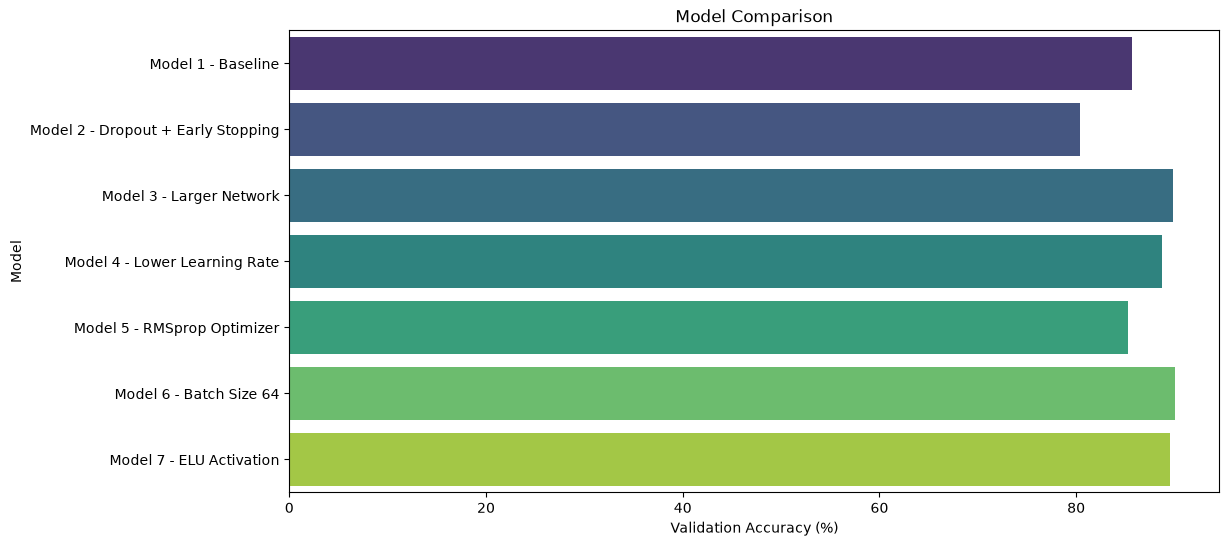

In [58]:
# Visualize model performance

plt.figure(figsize=(12, 6))

sns.barplot(data=comparison_results, x="Validation Accuracy", y="Model", palette="viridis")

plt.title("Model Comparison")
plt.xlabel("Validation Accuracy (%)")
plt.ylabel("Model")

plt.show()

## 17. Final Model Selection

Model 6 was selected as the final model.

### Selected Configuration

- Dense(128, ReLU)
- Dense(64, ReLU)
- Dense(32, ReLU)
- Dense(7, Softmax)

### Training Configuration

- Optimizer: Adam
- Learning Rate: 0.001
- Batch Size: 64

### Selection Rationale

Model 6 achieved the highest validation accuracy observed during experimentation while maintaining excellent generalization characteristics.

This configuration outperformed all other tested hyperparameter combinations and demonstrated a smaller training-to-validation accuracy gap than previous models.

## 18. Final Model Evaluation

After selecting the strongest candidate during validation testing, the final model is evaluated on the held-out test dataset.

The test dataset was not used during training or hyperparameter tuning and therefore provides the most unbiased estimate of real-world performance.

In [59]:
# Evaluate final model on unseen test data

test_loss_6, test_accuracy_6 = model_6.evaluate(X_test_scaled, y_test_encoded, verbose=1)

print(f"Final Model Test Accuracy: {test_accuracy_6:.4f}")
print(f"Final Model Test Loss: {test_loss_6:.4f}")

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9000 - loss: 0.2489
Final Model Test Accuracy: 0.9000
Final Model Test Loss: 0.2489


### Final Evaluation Findings

The selected model achieved a test accuracy of 90.00% on previously unseen data.

Performance on the test dataset closely matched validation performance, indicating strong generalization and minimal overfitting.

Compared with the baseline neural network, the final model improved test accuracy by approximately 4.5 percentage points. The most significant contribution to this improvement came from increasing network capacity and optimizing batch size.

These results demonstrate that careful hyperparameter tuning can substantially improve model performance while maintaining strong generalization characteristics.

### Classification Report

A classification report provides detailed performance metrics for each forest cover class, including precision, recall, and F1-score.

These metrics are especially important because the dataset contains significant class imbalance. Accuracy alone may not fully describe model performance across all cover types.

In [60]:
# Generate final model predictions

y_pred_probs = model_6.predict(X_test_scaled)

y_pred = np.argmax(y_pred_probs, axis=1)

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


In [61]:
# Display classification report

print(classification_report(y_test_encoded, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.91      0.90     31776
           1       0.93      0.90      0.91     42496
           2       0.86      0.93      0.89      5363
           3       0.86      0.70      0.77       412
           4       0.77      0.75      0.76      1424
           5       0.82      0.75      0.78      2605
           6       0.92      0.93      0.92      3076

    accuracy                           0.90     87152
   macro avg       0.86      0.84      0.85     87152
weighted avg       0.90      0.90      0.90     87152



### Confusion Matrix

The confusion matrix visualizes model performance across all classes and helps identify patterns of misclassification.

This allows us to determine which forest cover types are most frequently confused with one another.

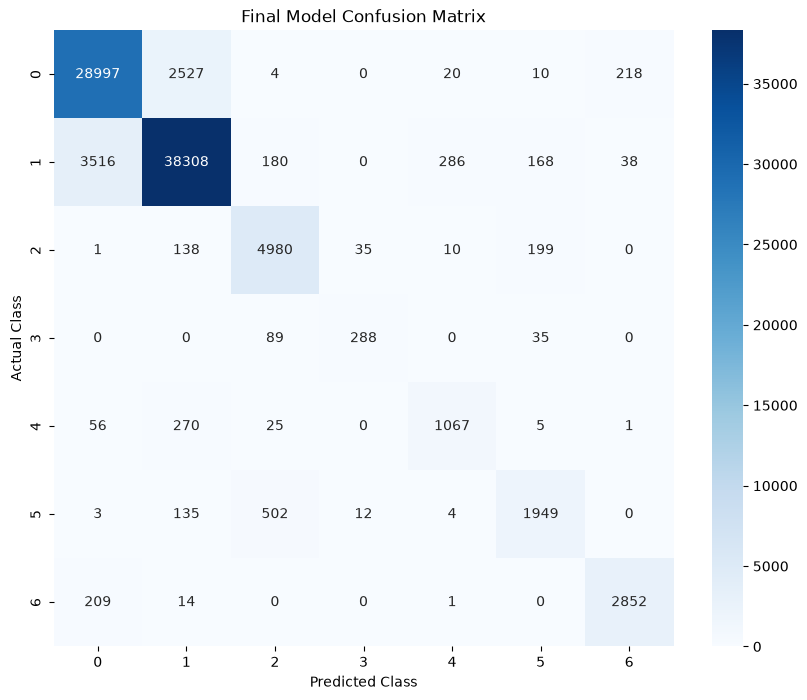

In [62]:
# Generate confusion matrix

cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

## 19. Model Persistence

The final model is saved and reloaded to demonstrate reproducibility and deployment readiness.

Saving trained models allows them to be reused without repeating the training process.

In [63]:
# Save final model

model_6.save("../models/final_forest_cover_model.keras")

print("Model saved successfully.")


Model saved successfully.


In [64]:
# Load saved model

final_model = keras.models.load_model("../models/final_forest_cover_model.keras")

print("Model loaded successfully.")

Model loaded successfully.


In [65]:
# Verify loaded model performance

loaded_loss, loaded_accuracy = final_model.evaluate(X_test_scaled, y_test_encoded, verbose=0)

print(f"Loaded Model Accuracy: {loaded_accuracy:.4f}")

Loaded Model Accuracy: 0.9000


### Classification Report Findings

The final model achieved strong performance across all classes, with F1-scores ranging from 0.76 to 0.92.

Performance was strongest for Classes 0, 1, and 6, all of which achieved F1-scores above 0.89. The weakest performance occurred for Classes 3 and 4, which also represented relatively small portions of the dataset.

The confusion matrix revealed that the most common classification errors occurred between Classes 0 and 1. This suggests that these forest cover types share similar environmental characteristics, making them more difficult to distinguish using the available cartographic variables.

Despite significant class imbalance, the model maintained strong precision and recall across all classes, demonstrating effective generalization and robustness.

# 20. Conclusions

## Project Summary

The objective of this project was to develop a deep learning classifier capable of predicting forest cover type using cartographic variables collected from the Roosevelt National Forest in northern Colorado.

The dataset contained 581,012 observations and 54 input features describing elevation, slope, hydrology, roadways, hillshade measurements, wilderness areas, and soil types. The target variable consisted of seven forest cover classes.

---

## Data Exploration Findings

Initial exploration revealed several important characteristics:

- The dataset contained no missing values.
- No duplicate observations were identified.
- Numerical and binary features were already well structured.
- Significant class imbalance was present, with Classes 1 and 2 representing approximately 85% of the dataset while Class 4 represented less than 1%.

Numerical features were standardized before model training, while binary one-hot encoded features remained unchanged.

---

## Baseline Model Performance

A baseline neural network containing two hidden layers was developed as the initial benchmark.

### Baseline Architecture

- Dense(64, ReLU)
- Dense(32, ReLU)
- Dense(7, Softmax)

### Baseline Results

- Validation Accuracy: 85.64%
- Test Accuracy: 85.55%

The baseline model demonstrated good performance and minimal overfitting, providing a strong foundation for further experimentation.

---

## Hyperparameter Tuning Results

Several controlled experiments were conducted to improve model performance.

### Model 2 - Dropout and Early Stopping

Result:

- Validation Accuracy: 80.39%

Finding:

Regularization reduced performance because the baseline model was not significantly overfitting.

---

### Model 3 - Increased Network Capacity

Result:

- Validation Accuracy: 89.84%
- Test Accuracy: 89.84%

Finding:

Increasing the number of hidden layers and neurons significantly improved performance, indicating that the baseline model lacked sufficient representational capacity.

---

### Model 4 - Reduced Learning Rate

Result:

- Validation Accuracy: 88.77%

Finding:

A lower learning rate produced stable training but did not outperform the default Adam configuration within the fixed training budget.

---

### Model 5 - RMSprop Optimizer

Result:

- Best Validation Accuracy: 85.26%

Finding:

RMSprop did not outperform Adam and produced less stable convergence.

---

### Model 6 - Batch Size 64

Result:

- Validation Accuracy: 90.05%
- Test Accuracy: 90.00%

Finding:

Increasing batch size improved generalization and produced the best overall model.

---

### Model 7 - ELU Activation Function

Result:

- Validation Accuracy: 89.56%

Finding:

ELU performed well but did not outperform ReLU.

---

## Final Model

### Architecture

- Dense(128, ReLU)
- Dense(64, ReLU)
- Dense(32, ReLU)
- Dense(7, Softmax)

### Training Configuration

- Optimizer: Adam
- Learning Rate: 0.001
- Batch Size: 64

### Performance

- Validation Accuracy: 90.05%
- Test Accuracy: 90.00%

The selected model improved test accuracy by approximately 4.5 percentage points compared with the baseline network.

---

## Error Analysis

The strongest performance was observed for Classes 0, 1, and 6.

The weakest performance occurred for Classes 3 and 4. These classes represented a smaller portion of the dataset and exhibited greater overlap with other cover types.

The confusion matrix revealed that the most common classification errors occurred between Classes 0 and 1, suggesting that these cover types share similar environmental characteristics and are difficult to distinguish using the available cartographic variables alone.

---

## Final Assessment

The project successfully demonstrated how deep learning can be applied to large-scale tabular environmental data.

Through systematic experimentation and controlled hyperparameter tuning, model performance improved from 85.55% to 90.00% test accuracy while maintaining strong generalization capability.

The final model provides a reliable classifier for predicting forest cover type and demonstrates the effectiveness of neural networks for multi-class classification problems involving cartographic and environmental variables.

# 21. Future Improvements

Several opportunities exist for further improving model performance:

### Address Class Imbalance

Potential approaches include:

- Class weighting
- Random oversampling
- SMOTE
- Focal loss

These techniques may improve performance on minority classes, particularly Classes 3 and 4.

---

### Additional Feature Engineering

Future work could include:

- Interaction features
- Polynomial relationships
- Terrain-derived indicators
- Feature selection techniques

---

### Advanced Deep Learning Architectures

Additional experiments could evaluate:

- Residual neural networks
- Wide-and-deep architectures
- Attention-based tabular models

---

### Automated Hyperparameter Optimization

Future studies could use:

- Grid Search
- Random Search
- Bayesian Optimization
- Keras Tuner

to identify optimal hyperparameter combinations more efficiently.

---

### Ensemble Learning

Combining predictions from multiple models may produce additional gains in classification performance and robustness.

---

## Final Reflection

The most impactful improvement observed during this project was increasing model capacity through additional hidden layers and neurons.

This finding highlights the importance of understanding the underlying learning limitations of a model before introducing additional regularization or more complex optimization strategies.